In [1]:
pip install datasets pandas

   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ---------------------------------------- 604.4/604.4 kB 3.7 MB/s  0:00:00
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ------------------------ --------------- 524.3/857.0 kB 4.0 MB/s eta 0:00:01
   ---------------------------------------- 857.0/857.0 kB 3.1 MB/s  0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   -------- ------------------------------- 0.8/3.9 MB 4.6 MB/s eta 0:00:01
   ------------------ --------------------- 1.8/3.9 MB 4.8 MB/s eta 0:00:01
   -------------------------- ------------- 2.6/3.9 MB 4.8 MB/s eta 0:00:01
   ------------------------------------- -- 3.7/3.9 MB 4.4 MB/s eta 0:00:01
   ---------------------------------------- 3.9/3.9 MB 4.3 MB/s  0:00:00

   - --------------------------------------  1/21 [truststore]
   --- ------------------------------------  2/21 [tqdm]
   --- ------------------------------------  2/21 [tqdm]


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\nithi\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [7]:
from datasets import load_dataset
import pandas as pd
from itertools import islice

# Stream the dataset without downloading everything
dataset = load_dataset(
    "jananisrik/indian-railways-runs",
    split="train",
    streaming=True
)


dataset = dataset.shuffle(
    seed=42,
    buffer_size=50000
)


rows = list(islice(dataset, 10000))


df = pd.DataFrame(rows)


df.to_csv(
    "railway_dataset_10000.csv",
    index=False
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Resolving data files:   0%|          | 0/12935 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/12935 [00:00<?, ?it/s]

Dataset shape: (10000, 24)
Columns: ['date', 'train_no', 'train_name', 'train_type', 'seq', 'station_code', 'halts_here', 'sch_arrival', 'sch_arrival_date', 'sch_departure', 'sch_departure_date', 'act_arrival', 'act_arrival_date', 'act_departure', 'act_departure_date', 'delay_arrival_min', 'delay_departure_min', 'platform', 'distance_km', 'lat', 'lng', 'departed', 'reported', 'reported_at']
         date train_no                         train_name    train_type  \
0  2021-12-09    14726            Bhiwani Jn. MTJ BNW EXP           MEX   
1  2026-08-19    15507  Patliputra DBG-PPTA INTERCITY EXP           MEX   
2  2026-05-23    09822                       DHN SGAC SPL  MAIL/EXPRESS   
3  2023-06-03    34915  Lakshmikantapur NMKA - LKPR LOCAL           EMU   
4  2025-11-30    15507  Patliputra DBG-PPTA INTERCITY EXP           MEX   

     seq station_code  halts_here sch_arrival sch_arrival_date sch_departure  \
0   10.0         JREA           1       15:00      09 Dec 2021         15:0

In [5]:


from datasets import load_dataset

print("Loading dataset...")

dataset = load_dataset(
    "jananisrik/indian-railways-runs",
    split="train",
    streaming=True
)



Starting dataset download...
Loading dataset...


Resolving data files:   0%|          | 0/12935 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/12935 [00:00<?, ?it/s]

Dataset loaded successfully!


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline, Pipeline

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score
)

sns.set_theme(style="whitegrid")

In [2]:


df = pd.read_csv("railway_dataset_10000.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

print("Dataset Shape:", df.shape)
print("\nAvailable Columns:")
print(df.columns.tolist())

display(df.head())

Dataset Shape: (10000, 24)

Available Columns:
['date', 'train_no', 'train_name', 'train_type', 'seq', 'station_code', 'halts_here', 'sch_arrival', 'sch_arrival_date', 'sch_departure', 'sch_departure_date', 'act_arrival', 'act_arrival_date', 'act_departure', 'act_departure_date', 'delay_arrival_min', 'delay_departure_min', 'platform', 'distance_km', 'lat', 'lng', 'departed', 'reported', 'reported_at']


,date,train_no,train_name,train_type,seq,station_code,halts_here,sch_arrival,sch_arrival_date,sch_departure,...,act_departure_date,delay_arrival_min,delay_departure_min,platform,distance_km,lat,lng,departed,reported,reported_at
0,2021-12-09,14726,Bhiwani Jn. MTJ BNW EXP,MEX,10.0,JREA,1,15:00,09 Dec 2021,15:01,...,09 Dec 2021,20.0,19.0,1.0,71.996,27.472952,77.038293,1,1,2021-12-09T15:20:10.167419+05:30
1,2026-08-19,15507,Patliputra DBG-PPTA INTERCITY EXP,MEX,5.0,KML,1,03:11,19 Aug 2026,03:13,...,19 Aug 2026,NaN,3.0,1.0,22.962,26.324692,85.817653,1,1,2026-08-19T03:11:55.289691+05:30
2,2026-05-23,9822,DHN SGAC SPL,MAIL/EXPRESS,111.0,MKP,1,17:28,23 May 2026,17:30,...,23 May 2026,172.0,174.0,1.0,639.969,25.064019,81.097851,1,1,2026-05-23T20:20:05.774687+05:30
3,2023-06-03,34915,Lakshmikantapur NMKA - LKPR LOCAL,EMU,NaN,KNJI,1,08:02,03 Jun 2023,08:03,...,03 Jun 2023,NaN,0.0,1.0,NaN,NaN,NaN,0,0,NaN
4,2025-11-30,15507,Patliputra DBG-PPTA INTERCITY EXP,MEX,20.0,RUSD,1,04:41,30 Nov 2025,04:43,...,30 Nov 2025,11.0,13.0,1.0,90.409,26.415337,85.519302,1,1,2025-11-30T04:55:30.800716+05:30


In [3]:

required = ["date", "sch_arrival", "delay_arrival_min"]

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Required columns missing: {missing}")

df = df.drop_duplicates().copy()

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["delay_arrival_min"] = pd.to_numeric(
    df["delay_arrival_min"], errors="coerce"
)

df = df.dropna(
    subset=["date", "delay_arrival_min"]
).copy()

df = df.sort_values("date").reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

Cleaned Dataset Shape: (5086, 24)

Missing Values:
 date                      0
train_no                  0
train_name                0
train_type                0
seq                       0
station_code              0
halts_here                0
sch_arrival               0
sch_arrival_date          0
sch_departure             0
sch_departure_date        0
act_arrival               0
act_arrival_date          0
act_departure           810
act_departure_date      810
delay_arrival_min         0
delay_departure_min     835
platform                943
distance_km               0
lat                    1731
lng                    1731
departed                  0
reported                  0
reported_at            1732
dtype: int64


In [4]:

arrival_time = df["sch_arrival"].astype(str).str.extract(
    r"(\d{1,2}):(\d{2})"
)

df["Arrival_Hour"] = pd.to_numeric(
    arrival_time[0], errors="coerce"
)

df["Arrival_Minute"] = pd.to_numeric(
    arrival_time[1], errors="coerce"
)

df["Month"] = df["date"].dt.month
df["Day_Of_Week"] = df["date"].dt.dayofweek

print("Feature Engineering Completed")

display(df[[
    "date", "sch_arrival",
    "Arrival_Hour", "Arrival_Minute",
    "Month", "Day_Of_Week",
    "delay_arrival_min"
]].head())

Feature Engineering Completed


,date,sch_arrival,Arrival_Hour,Arrival_Minute,Month,Day_Of_Week,delay_arrival_min
0,2020-01-01,06:37,6,37,1,2,3.0
1,2020-01-01,04:18,4,18,1,2,4.0
2,2020-01-01,04:47,4,47,1,2,2.0
3,2020-01-02,11:46,11,46,1,3,0.0
4,2020-01-02,06:37,6,37,1,3,11.0


In [5]:

df["Delay_Category"] = np.select(
    [
        df["delay_arrival_min"] <= 15,
        df["delay_arrival_min"] <= 60
    ],
    ["On-Time", "Moderate"],
    default="Major"
)

print(df["Delay_Category"].value_counts())

Delay_Category
On-Time     3721
Moderate     726
Major        639
Name: count, dtype: int64


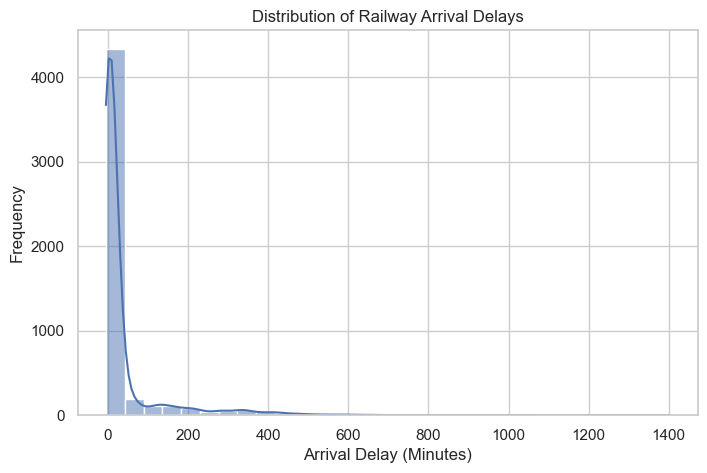

In [6]:

plt.figure(figsize=(8, 5))

sns.histplot(
    df["delay_arrival_min"],
    bins=30,
    kde=True
)

plt.title("Distribution of Railway Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Frequency")
plt.show()

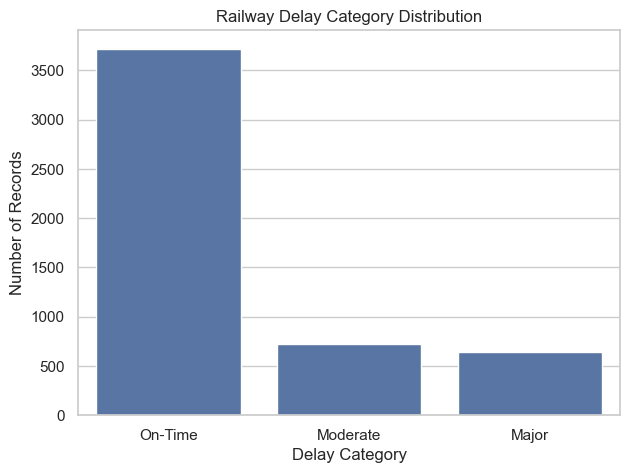

In [7]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Delay_Category",
    order=["On-Time", "Moderate", "Major"]
)

plt.title("Railway Delay Category Distribution")
plt.xlabel("Delay Category")
plt.ylabel("Number of Records")
plt.show()

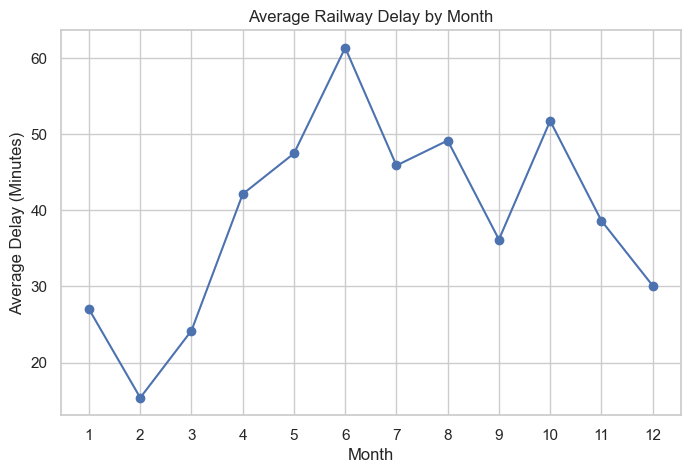

In [8]:

monthly_delay = df.groupby("Month")[
    "delay_arrival_min"
].mean()

plt.figure(figsize=(8, 5))

plt.plot(
    monthly_delay.index,
    monthly_delay.values,
    marker="o"
)

plt.title("Average Railway Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(range(1, 13))
plt.show()

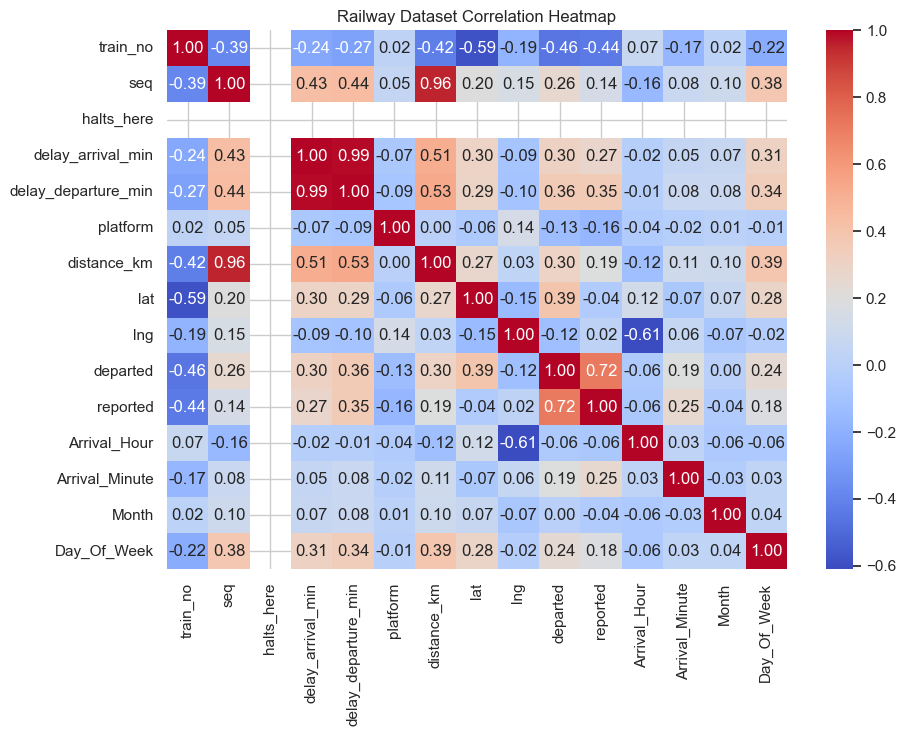

In [9]:

numeric_data = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Railway Dataset Correlation Heatmap")
plt.show()

In [10]:

unique_dates = sorted(df["date"].unique())

if len(unique_dates) < 2:
    raise ValueError("Not enough different dates for a chronological split.")

cutoff = unique_dates[int(len(unique_dates) * 0.80)]

train_df = df[df["date"] < cutoff].copy()
test_df = df[df["date"] >= cutoff].copy()

print("Training Records:", len(train_df))
print("Testing Records:", len(test_df))
print("Training ends:", train_df["date"].max())
print("Testing starts:", test_df["date"].min())

Training Records: 4014
Testing Records: 1072
Training ends: 2025-09-27 00:00:00
Testing starts: 2025-09-28 00:00:00


In [11]:

reg_features = [
    "seq", "halts_here", "distance_km",
    "lat", "lng", "Arrival_Hour",
    "Arrival_Minute", "Month", "Day_Of_Week"
]

reg_features = [
    col for col in reg_features if col in df.columns
]

X_reg = df[reg_features].copy()

# Convert features to numeric
X_reg = X_reg.apply(pd.to_numeric, errors="coerce")

y_reg = df["delay_arrival_min"]

X_reg_train = X_reg.loc[train_df.index]
X_reg_test = X_reg.loc[test_df.index]

y_reg_train = y_reg.loc[train_df.index]
y_reg_test = y_reg.loc[test_df.index]

print("Regression Features:", reg_features)
print("Training Shape:", X_reg_train.shape)
print("Testing Shape:", X_reg_test.shape)

Regression Features: ['seq', 'halts_here', 'distance_km', 'lat', 'lng', 'Arrival_Hour', 'Arrival_Minute', 'Month', 'Day_Of_Week']
Training Shape: (4014, 9)
Testing Shape: (1072, 9)


In [12]:

simple_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

simple_model.fit(
    X_reg_train[["Arrival_Hour"]],
    y_reg_train
)

simple_pred = simple_model.predict(
    X_reg_test[["Arrival_Hour"]]
)

print("Simple Linear Regression Completed")

Simple Linear Regression Completed


In [13]:

multiple_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

multiple_model.fit(X_reg_train, y_reg_train)

multiple_pred = multiple_model.predict(X_reg_test)

print("Multiple Linear Regression Completed")

Multiple Linear Regression Completed


In [14]:

polynomial_model = make_pipeline(
    SimpleImputer(strategy="median"),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

polynomial_model.fit(
    X_reg_train[["Arrival_Hour"]],
    y_reg_train
)

polynomial_pred = polynomial_model.predict(
    X_reg_test[["Arrival_Hour"]]
)

print("Polynomial Regression Completed")

Polynomial Regression Completed


In [15]:

reg_results = []

for name, pred in [
    ("Simple Linear Regression", simple_pred),
    ("Multiple Linear Regression", multiple_pred),
    ("Polynomial Regression", polynomial_pred)
]:

    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_test, pred),
        "MSE": mean_squared_error(y_reg_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, pred)),
        "R2 Score": r2_score(y_reg_test, pred)
    })

reg_results = pd.DataFrame(reg_results)

display(reg_results)

,Model,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,74.069942,16992.785149,130.356377,-0.123039
1,Multiple Linear Regression,59.911577,9914.670787,99.572440,0.344748
2,Polynomial Regression,77.099068,16476.067644,128.359135,-0.088890


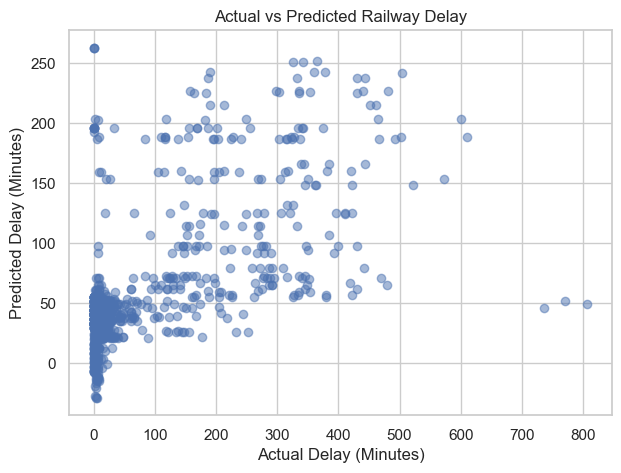

In [16]:

plt.figure(figsize=(7, 5))

plt.scatter(
    y_reg_test,
    multiple_pred,
    alpha=0.5
)

plt.xlabel("Actual Delay (Minutes)")
plt.ylabel("Predicted Delay (Minutes)")
plt.title("Actual vs Predicted Railway Delay")

plt.show()

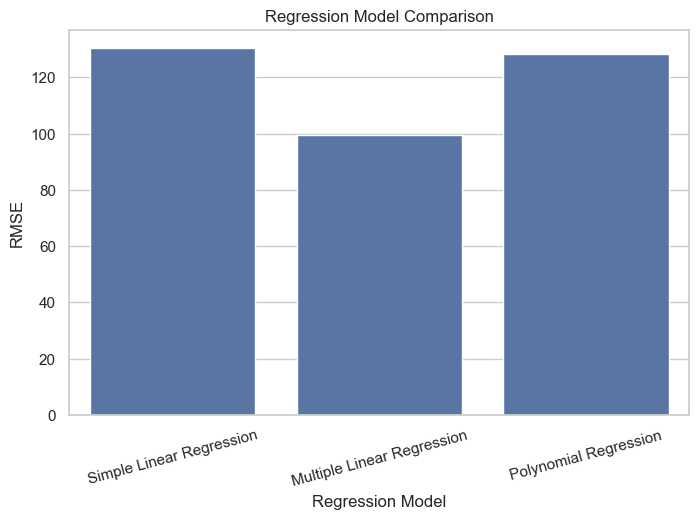

In [17]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=reg_results,
    x="Model",
    y="RMSE"
)

plt.title("Regression Model Comparison")
plt.xlabel("Regression Model")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.show()

In [18]:

class_features = [
    "seq", "halts_here", "distance_km",
    "lat", "lng", "Arrival_Hour",
    "Arrival_Minute", "Month", "Day_Of_Week",
    "train_type", "station_code"
]

class_features = [
    col for col in class_features if col in df.columns
]

X_class = df[class_features].copy()
y_class = df["Delay_Category"]

X_train = X_class.loc[train_df.index].copy()
X_test = X_class.loc[test_df.index].copy()

y_train = y_class.loc[train_df.index]
y_test = y_class.loc[test_df.index]

# Identify numeric and categorical features
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numeric Features: ['seq', 'halts_here', 'distance_km', 'lat', 'lng', 'Arrival_Hour', 'Arrival_Minute', 'Month', 'Day_Of_Week']
Categorical Features: ['train_type', 'station_code']


In [27]:
numeric_preprocessor = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

categorical_preprocessor = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False)
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features)
    ],
    sparse_threshold=0
)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


In [28]:


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Naive Bayes": GaussianNB(),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    )
}

trained_models = {}
predictions = {}

for name, classifier in models.items():

    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    trained_models[name] = model
    predictions[name] = model.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions[name]))

    print(classification_report(
        y_test,
        predictions[name],
        zero_division=0
    ))


 Logistic Regression
Accuracy: 0.6091417910447762
              precision    recall  f1-score   support

       Major       0.86      0.51      0.64       271
    Moderate       0.28      0.54      0.37       156
     On-Time       0.71      0.67      0.69       645

    accuracy                           0.61      1072
   macro avg       0.62      0.57      0.56      1072
weighted avg       0.68      0.61      0.63      1072


 KNN
Accuracy: 0.7201492537313433
              precision    recall  f1-score   support

       Major       0.81      0.58      0.68       271
    Moderate       0.33      0.32      0.32       156
     On-Time       0.78      0.87      0.82       645

    accuracy                           0.72      1072
   macro avg       0.64      0.59      0.61      1072
weighted avg       0.72      0.72      0.71      1072


 Naive Bayes
Accuracy: 0.4542910447761194
              precision    recall  f1-score   support

       Major       0.38      0.99      0.55       271


In [23]:

class_results = []

for name, pred in predictions.items():

    class_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, average="weighted", zero_division=0
        )
    })

class_results = pd.DataFrame(class_results)

class_results = class_results.sort_values(
    "F1 Score", ascending=False
)

display(class_results)

,Model,Accuracy,Precision,Recall,F1 Score
4,SVM,0.745336,0.746545,0.745336,0.720283
1,KNN,0.720149,0.720766,0.720149,0.714070
3,Decision Tree,0.733209,0.736000,0.733209,0.691393
0,Logistic Regression,0.609142,0.684200,0.609142,0.628742
2,Naive Bayes,0.454291,0.658221,0.454291,0.434540


In [24]:

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_test)

    try:
        auc = roc_auc_score(
            y_test,
            probabilities,
            labels=model.named_steps["classifier"].classes_,
            multi_class="ovr",
            average="macro"
        )

        print(name, "ROC-AUC:", round(auc, 4))

    except ValueError as error:
        print(name, "ROC-AUC unavailable:", error)

Logistic Regression ROC-AUC: 0.7753
KNN ROC-AUC: 0.773
Naive Bayes ROC-AUC: 0.6798
Decision Tree ROC-AUC: 0.6944
SVM ROC-AUC: 0.8319


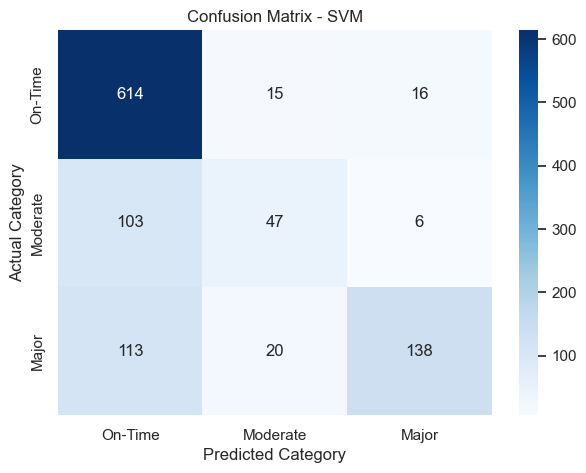

Best Model: SVM


In [25]:

best_name = class_results.iloc[0]["Model"]

best_model = trained_models[best_name]
best_pred = predictions[best_name]

labels = ["On-Time", "Moderate", "Major"]

cm = confusion_matrix(
    y_test,
    best_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.show()

print("Best Model:", best_name)

In [29]:

reg_results.to_csv(
    "railpulse_regression_results.csv",
    index=False
)

class_results.to_csv(
    "railpulse_classification_results.csv",
    index=False
)

